# What is Embedded method in Feature Selection?

- There are certain Machine Learning models, which along with training the model, also gives feature importance. We can use these models as feature selection.

- This method of feature selection is called `embedded technique/method` bcz here finding important feature is embedded along with training the model.

- One of such algorithm is LinearRegression. We trained this multiple times so we are skipping this algorithm.

- Let's see how we can use `Lasso - A Regularization Algorithm` for feature selection. 

In [1]:
import pandas as pd
import numpy as np

# Pandas
pd.set_option('display.float_format', '{:.4f}'.format)

# NumPy
np.set_printoptions(suppress=True, precision=4)

from sklearn import datasets
from sklearn.model_selection import train_test_split, cross_val_score

In [2]:
# Load Pima Indians Diabetes Dataset

df = pd.read_csv('https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv')

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6000,0.6270,50,1
1,1,85,66,29,0,26.6000,0.3510,31,0
2,8,183,64,0,0,23.3000,0.6720,32,1
3,1,89,66,23,94,28.1000,0.1670,21,0
4,0,137,40,35,168,43.1000,2.2880,33,1


In [3]:
# Splitting data into train and test

x = df.drop(columns = ['Outcome'])
y = df.drop(columns = x)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

print(f"""Shape of Data
==================
Training Data: {x_train.shape}
Test data: {x_test.shape} """)

Shape of Data
Training Data: (614, 8)
Test data: (154, 8) 


In [4]:
# Our data set is not scaled and linear models require scaled data. So let's scale the dataset

from sklearn.preprocessing import StandardScaler

ss = StandardScaler().set_output(transform = 'pandas')

x_train = ss.fit_transform(x_train)
x_test = ss.transform(x_test)

x_train.describe()

# Mean is approx 0 and std_deviation is approx 1, for all features. 
# So, Standard Scaler worked

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
count,614.0000,614.0000,614.0000,614.0000,614.0000,614.0000,614.0000,614.0000
mean,0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
std,1.0008,1.0008,1.0008,1.0008,1.0008,1.0008,1.0008,1.0008
min,-1.1423,-3.8330,-3.4915,-1.2508,-0.6785,-4.1751,-1.1611,-1.0422
25%,-0.8468,-0.7036,-0.3479,-1.2508,-0.6785,-0.6338,-0.6712,-0.7879
50%,-0.2560,-0.1346,0.1591,0.1375,-0.5368,0.0154,-0.3127,-0.3642
75%,0.6303,0.6241,0.5648,0.7686,0.3946,0.5958,0.4057,0.6527
max,3.2892,2.4259,2.6943,4.9965,6.5839,4.6257,5.7023,3.2797


In [5]:
# Training Lasso model

from sklearn.linear_model import Lasso

lasso = Lasso(alpha = 0.1)
# alpha is a regularization term popularily set between 0.01-0.1. We will discuss it in dedicated session for regularization

lasso.fit(x_train, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary `.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


In [6]:
# Getting the importance of each feature
lasso.coef_

# It shows the weightage of each feature
# Also, notice, many values are 0. 
# So this is a good interview question 'Why Lasso creates sparsity (Sparcity means so many values are 0)

array([ 0.    ,  0.1268, -0.    ,  0.    ,  0.    ,  0.0048,  0.    ,
        0.    ])

<Axes: >

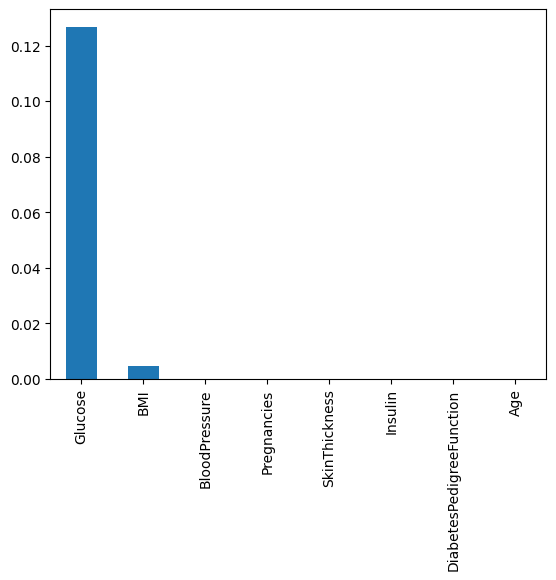

In [7]:
# Plot the weightage

feature_imp = pd.Series(np.abs(lasso.coef_), index = x.columns).sort_values(ascending = False)

feature_imp.plot(kind = 'bar')

# Decision Tree and Random Forest

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [9]:
dt = DecisionTreeClassifier(random_state = 1)
rfc = RandomForestClassifier(random_state = 1)

rfc.fit(x_train, y_train)
dt.fit(x_train, y_train)

c:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",1
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

In [10]:
# Get feature importance
dt.feature_importances_

array([0.0609, 0.3313, 0.1144, 0.0484, 0.0324, 0.1669, 0.1032, 0.1425])

<Axes: >

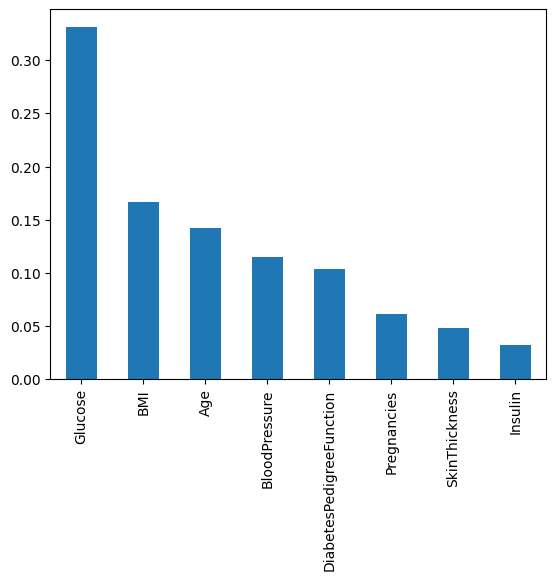

In [11]:
# Plotting for Desision Tree
sel_features = pd.Series(np.abs(dt.feature_importances_), index = x_train.columns)
sel_features.sort_values(ascending = False).plot(kind = 'bar')

<Axes: >

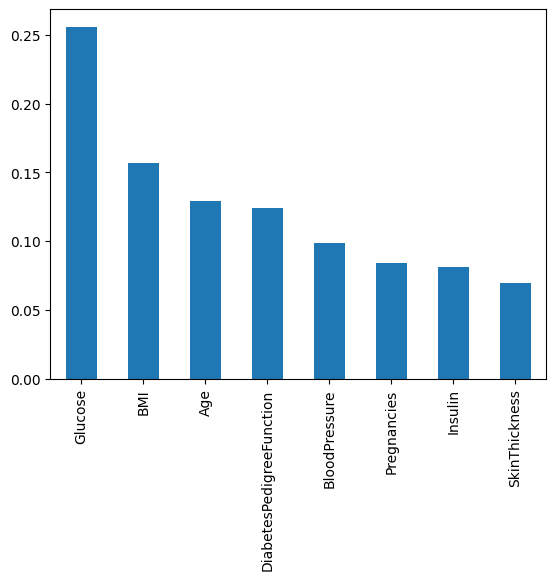

In [12]:
# Plotting for Random Forest
sel_features = pd.Series(np.abs(rfc.feature_importances_), index = x_train.columns)
sel_features.sort_values(ascending = False).plot(kind = 'bar')

# SelectFromModel

In [13]:
# Load Pima Indians Diabetes Dataset

df = pd.read_csv('https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv')

# Splitting data into train and test

x = df.drop(columns = ['Outcome'])
y = df.drop(columns = x)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

print(f"""Shape of Data
==================
Training Data: {x_train.shape}
Test data: {x_test.shape} """)

Shape of Data
Training Data: (614, 8)
Test data: (154, 8) 


In [14]:
x_train.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
663,9,145,80,46,130,37.9000,0.6370,40
712,10,129,62,36,0,41.2000,0.4410,38
161,7,102,74,40,105,37.2000,0.2040,45
509,8,120,78,0,0,25.0000,0.4090,64
305,2,120,76,37,105,39.7000,0.2150,29


In [15]:
from sklearn.feature_selection import SelectFromModel

In [16]:
dt = DecisionTreeClassifier(random_state = 1)
sfm = SelectFromModel(estimator = dt, threshold = 0.13).set_output(transform = 'pandas')
# Threshold = 0.13 means drop all features whose importance < 0.13

# Fitting SelectFromModel
x_train_trans = sfm.fit_transform(x_train, y_train)
x_train_trans

# See these removes the features with importance<0.13

,Glucose,BMI,Age
663,145,37.9000,40
712,129,41.2000,38
161,102,37.2000,45
509,120,25.0000,64
305,120,39.7000,29
...,...,...,...
645,157,39.4000,30
715,187,33.9000,34
72,126,43.4000,42
235,171,43.6000,26


# Recursive Feature Elimination (RFE)

In [17]:
list(rfc.feature_importances_).index(rfc.feature_importances_.min())

df.drop()

ValueError: Need to specify at least one of 'labels', 'index' or 'columns'

In [ ]:
def RFE(df):

    '''
    Run this recurssive function only on Iris dataset as this is just for understanding for RFE works.
    Else, we already have RFE class in scikit learn
    '''
    
    if len(df.columns) == 2:
        return df.columns

    x = df.drop(columns = 'species')
    y = df.drop(columns = x)

    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

    dt = DecisionTreeClassifier(random_state = 1)

    dt.fit(x_train, y_train)

    # DF for feature importances
    # rename_axis give the name to the index column
    fet_imp = pd.DataFrame(
        dt.feature_importances_, 
        index = x.columns, 
        columns = ['Importance']
        ).rename_axis('Features')
    
    display(fet_imp)

    idx_col_to_drop = list(dt.feature_importances_).index(dt.feature_importances_.min())

    print(f"""*****Dropped Column*****
Column: {x.columns[idx_col_to_drop]}
Importance: {dt.feature_importances_.min()}
--------------------------------------------------""")

    df = df.drop(columns = x.columns[idx_col_to_drop])

    return RFE(df)

In [ ]:
df = pd.read_csv('https://gist.githubusercontent.com/curran/a08a1080b88344b0c8a7/raw/0e7a9b0a5d22642a06d3d5b9bcbad9890c8ee534/iris.csv')
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1000,3.5000,1.4000,0.2000,setosa
1,4.9000,3.0000,1.4000,0.2000,setosa
2,4.7000,3.2000,1.3000,0.2000,setosa
3,4.6000,3.1000,1.5000,0.2000,setosa
4,5.0000,3.6000,1.4000,0.2000,setosa


In [ ]:
RFE(df = df)

,Importance
Features,
sepal_length,0.0075
sepal_width,0.0188
petal_length,0.0758
petal_width,0.8978


*****Dropped Column*****
Column: sepal_length
Importance: 0.007520367662419047
--------------------------------------------------


,Importance
Features,
sepal_width,0.0313
petal_length,0.0758
petal_width,0.8928


*****Dropped Column*****
Column: sepal_width
Importance: 0.031334865260079385
--------------------------------------------------


,Importance
Features,
petal_length,0.0920
petal_width,0.9080


*****Dropped Column*****
Column: petal_length
Importance: 0.09200619730862707
--------------------------------------------------


Index(['petal_width', 'species'], dtype='object')

In [ ]:
pd.DataFrame([1, 2, 3, 4, 5], index = ['A', 'B', 'C', 'D', 'E'], columns = ['Roll_NO'])
# pd.DataFrame([1, 2, 3, 4, 5], index = ['A', 'B', 'C', 'D', 'E'], columns = ['Roll_NO']).rename_axis('STUDENT')

,Roll_NO
A,1
B,2
C,3
D,4
E,5


In [ ]:
# Using scikit learn library

from sklearn.feature_selection import RFE

In [ ]:
display(x_train)
display(y_train)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
663,9,145,80,46,130,37.9000,0.6370,40
712,10,129,62,36,0,41.2000,0.4410,38
161,7,102,74,40,105,37.2000,0.2040,45
509,8,120,78,0,0,25.0000,0.4090,64
305,2,120,76,37,105,39.7000,0.2150,29
...,...,...,...,...,...,...,...,...
645,2,157,74,35,440,39.4000,0.1340,30
715,7,187,50,33,392,33.9000,0.8260,34
72,13,126,90,0,0,43.4000,0.5830,42
235,4,171,72,0,0,43.6000,0.4790,26


,Outcome
663,1
712,1
161,0
509,0
305,0
...,...
645,0
715,1
72,1
235,1


In [ ]:
rfc = RandomForestClassifier(random_state = 1)

# Initialize RFE
rfe = RFE(estimator = rfc, n_features_to_select = 2)

# fit rfe
rfe.fit(x_train, y_train)

C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1336: DataConvers

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).",RandomForestC...andom_state=1)
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",2
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0


In [ ]:
# print rankings
feature_ranking = rfe.ranking_

print(feature_ranking)

[5 1 4 7 6 1 2 3]


In [ ]:
# See the features in order of importance

for i, feature in enumerate(x.columns):
    print(f"{feature}: {feature_ranking[i]}")

Pregnancies: 5
Glucose: 1
BloodPressure: 4
SkinThickness: 7
Insulin: 6
BMI: 1
DiabetesPedigreeFunction: 2
Age: 3


# Sure — here's a clean **JupyterLab Markdown cell** version you can paste directly:

````markdown
## Why are there TWO `1`s (Glucose and BMI)?

Because **RFE gives rank `1` to every feature that it ultimately keeps/selects**.

If you created RFE like:

```python
RFE(estimator=dt, n_features_to_select=2)
````

then you asked RFE to **keep 2 features**.

### Example

| Feature   |          Ranking |
| --------- | ---------------: |
| Feature 1 |                5 |
| Feature 2 | **1** ← Selected |
| Feature 3 |                4 |
| Feature 4 |                7 |
| Feature 5 |                6 |
| Feature 6 | **1** ← Selected |
| Feature 7 |                2 |
| Feature 8 |                3 |

So, the two features with **ranking `1`** are the **two selected features**.

### How RFE Ranking Works

RFE repeatedly removes features:

```text
8 Features
    ↓
Remove least important feature
    ↓
7 Features
    ↓
Remove least important feature
    ↓
...
    ↓
2 Features  ← These get rank 1
```

Therefore:

* **Rank 1** → Selected features
* **Rank 2** → Feature eliminated in the last elimination
* **Rank 3** → Feature eliminated before that
* **Rank 4** → Feature eliminated before that
* And so on...

> **Important:** The final selected features are **not ranked 1st and 2nd**. They both receive **rank `1`** because both belong to the selected feature set.

So, if `n_features_to_select=2`, normally you will see **two features with ranking `1`**.

```
```


````markdown
## Why are there TWO `1`s (Glucose and BMI)?

Because **RFE gives rank `1` to every feature that it ultimately keeps/selects**.

If you created RFE like:

```python
RFE(estimator=dt, n_features_to_select=2)
````

then you asked RFE to **keep 2 features**.

### Example

| Feature   |          Ranking |
| --------- | ---------------: |
| Feature 1 |                5 |
| Feature 2 | **1** ← Selected |
| Feature 3 |                4 |
| Feature 4 |                7 |
| Feature 5 |                6 |
| Feature 6 | **1** ← Selected |
| Feature 7 |                2 |
| Feature 8 |                3 |

So, the two features with **ranking `1`** are the **two selected features**.

### How RFE Ranking Works

RFE repeatedly removes features:

```text
8 Features
    ↓
Remove least important feature
    ↓
7 Features
    ↓
Remove least important feature
    ↓
...
    ↓
2 Features  ← These get rank 1
```

Therefore:

* **Rank 1** → Selected features
* **Rank 2** → Feature eliminated in the last elimination
* **Rank 3** → Feature eliminated before that
* **Rank 4** → Feature eliminated before that
* And so on...

> **Important:** The final selected features are **not ranked 1st and 2nd**. They both receive **rank `1`** because both belong to the selected feature set.

So, if `n_features_to_select=2`, normally you will see **two features with ranking `1`**.

```
```


There is a variant of Recurssive Feature Elimination called **RFECV** stands for `Recurssive Feature Elimination CV`. It performs cross validation while eliminating features and so, give somewhat more accurate results than vanilla RFE technique.

Also, both has a parameter `step`, whose default value is 1. <br>
step is nothing just how many features to eliminate in one run. <br>
For example:  If set to 2, it eliminates 2 features in one run.

**Note: Generally step is set to 1. It is only increased if dataset is too large dimension (No.of Features)**

**Let's try RFECV**

In [ ]:
from sklearn.feature_selection import RFECV

In [ ]:
rfcv = RFECV(
    estimator = rfc,
    min_features_to_select = 3,
    cv = 5,
    verbose = True,
    n_jobs = -1).set_output(transform = 'pandas')

x_train_sel = rfcv.fit_transform(x_train, y_train)

Fitting estimator with 8 features.


C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
C:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


In [ ]:
x_train_sel

,Pregnancies,Glucose,BloodPressure,Insulin,BMI,DiabetesPedigreeFunction,Age
663,9,145,80,130,37.9000,0.6370,40
712,10,129,62,0,41.2000,0.4410,38
161,7,102,74,105,37.2000,0.2040,45
509,8,120,78,0,25.0000,0.4090,64
305,2,120,76,105,39.7000,0.2150,29
...,...,...,...,...,...,...,...
645,2,157,74,440,39.4000,0.1340,30
715,7,187,50,392,33.9000,0.8260,34
72,13,126,90,0,43.4000,0.5830,42
235,4,171,72,0,43.6000,0.4790,26


In [ ]:
rfcv.ranking_

array([1, 1, 1, 2, 1, 1, 1, 1])

In [ ]:
rfcv.support_

array([ True,  True,  True, False,  True,  True,  True,  True])

# Mutual Info Classif (Filter Based Feature Selection Method)

In [18]:
x_train

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
663,9,145,80,46,130,37.9000,0.6370,40
712,10,129,62,36,0,41.2000,0.4410,38
161,7,102,74,40,105,37.2000,0.2040,45
509,8,120,78,0,0,25.0000,0.4090,64
305,2,120,76,37,105,39.7000,0.2150,29
...,...,...,...,...,...,...,...,...
645,2,157,74,35,440,39.4000,0.1340,30
715,7,187,50,33,392,33.9000,0.8260,34
72,13,126,90,0,0,43.4000,0.5830,42
235,4,171,72,0,0,43.6000,0.4790,26


In [22]:
from sklearn.feature_selection import mutual_info_classif

# Calculate mutual info
mi = mutual_info_classif(x_train, y_train)

# print mutual info
for i, mutual_info in enumerate(mi):
    print(f"Feature{i}: Mutual Info = {mutual_info}")

Feature0: Mutual Info = 0.02670554835107941
Feature1: Mutual Info = 0.12537468950954733
Feature2: Mutual Info = 0.015216535989871494
Feature3: Mutual Info = 0.0
Feature4: Mutual Info = 0.02172525435148609
Feature5: Mutual Info = 0.0752218429485898
Feature6: Mutual Info = 0.017889310504225264
Feature7: Mutual Info = 0.044503352785939754


c:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [ ]:
mutual_info_df = pd.DataFrame(
    data = mi, 
    columns = ['Mutual Information'], 
    index= x_train.columns
    ).rename_axis('Feature')

mutual_info_df

,Mutual Information
Feature,
Pregnancies,0.0267
Glucose,0.1254
BloodPressure,0.0152
SkinThickness,0.0000
Insulin,0.0217
BMI,0.0752
DiabetesPedigreeFunction,0.0179
Age,0.0445


<Axes: xlabel='Feature'>

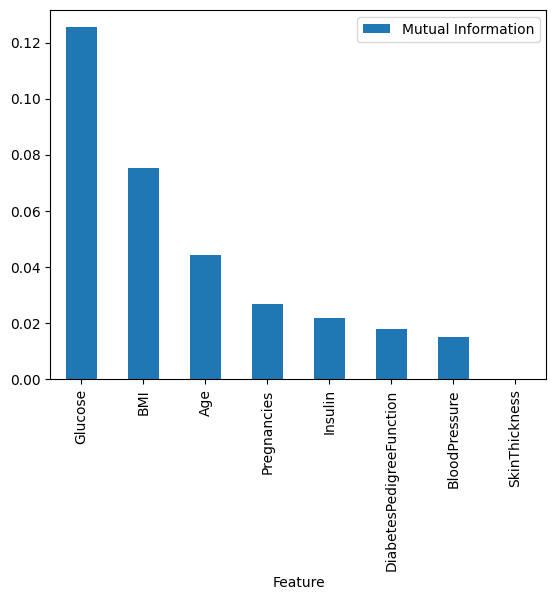

In [39]:
mutual_info_df.sort_values(by = 'Mutual Information', ascending=False).plot(kind = 'bar')

In [60]:
# We can also use mutual_info_classif with SelectKBest

from sklearn.feature_selection import SelectKBest

skb = SelectKBest(score_func = mutual_info_classif, k = 4).set_output(transform = 'pandas')

In [ ]:
x_train_trans = skb.fit_transform(x_train, y_train)

x_train_trans    # See, we are getting same 4 best columns

# Note: We also hace mutual_info_regression for regression problem

c:\Users\jugal\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,Pregnancies,Glucose,BMI,Age
663,9,145,37.9000,40
712,10,129,41.2000,38
161,7,102,37.2000,45
509,8,120,25.0000,64
305,2,120,39.7000,29
...,...,...,...,...
645,2,157,39.4000,30
715,7,187,33.9000,34
72,13,126,43.4000,42
235,4,171,43.6000,26
